<a href="https://colab.research.google.com/github/mf1060/ml-2026/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Michael Furey

Dr. Forouraghi

HW #6

November 2, 2026

# Introduction

The following is an analysis of a faces database. This notebook uses methods and documentation from two notebooks: (1) [07_dimensionality_reduction.ipynb](https://github.com/bforoura/ML26/blob/main/Module7_Dimensionality/07_dimensionality_reduction.ipynb) and [plant_classification.ipynb](https://github.com/bforoura/ML26/blob/main/Module7_Dimensionality/plant_classification.ipynb). The goal of this assignment is to use a PCA Analysis on the Olivetti faces dataset to observe changes in image quality.

This notebook uses code and methods from the class [End-to-End Machine Learning Project](https://github.com/bforoura/ML26/blob/main/Module2_ML_Projects/02_end_to_end_machine_learning_project.ipynb) and makes reference to our textbook (Aurélien Géron, Hands-On Machine Learning with SciKit-Learn and PyTorch (2025)) as well as the Chapter 8 overview.

# **1. Dataset Loading and Dimensionality Inspection**



In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt

# Loading dataset with reference to: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_olivetti_faces.html
olivetti = fetch_olivetti_faces()
# This setting returns features and targets as separate variables.
X, y = fetch_olivetti_faces(return_X_y=True)

We can see details for this dataset with the following function with code in reference to [08_unsupervised_learning.ipynb](https://github.com/bforoura/ML26/blob/main/Module8_Unsupervised/08_unsupervised_learning.ipynb). We can see that the dataset contains 10 samples from 40 individuals (400 individuals in total). Each image contains 4,096 dimensions in 64x64 resolution.

In [2]:
print(olivetti.DESCR)

.. _olivetti_faces_dataset:

The Olivetti faces dataset
--------------------------

`This dataset contains a set of face images`_ taken between April 1992 and
April 1994 at AT&T Laboratories Cambridge. The
:func:`sklearn.datasets.fetch_olivetti_faces` function is the data
fetching / caching function that downloads the data
archive from AT&T.

.. _This dataset contains a set of face images: https://cam-orl.co.uk/facedatabase.html

As described on the original website:

    There are ten different images of each of 40 distinct subjects. For some
    subjects, the images were taken at different times, varying the lighting,
    facial expressions (open / closed eyes, smiling / not smiling) and facial
    details (glasses / no glasses). All the images were taken against a dark
    homogeneous background with the subjects in an upright, frontal position
    (with tolerance for some side movement).

**Data Set Characteristics:**

=================   =====================
Classes              

The following produces a set of images in 4x5 format. We can also view the number of samples with code in reference to [08_unsupervised_learning.ipynb](https://github.com/bforoura/ML26/blob/main/Module8_Unsupervised/08_unsupervised_learning.ipynb).  This uses code from the following [site](https://marziosala.github.io/eigenfaces/) to perform visualization with a 4x5 array:


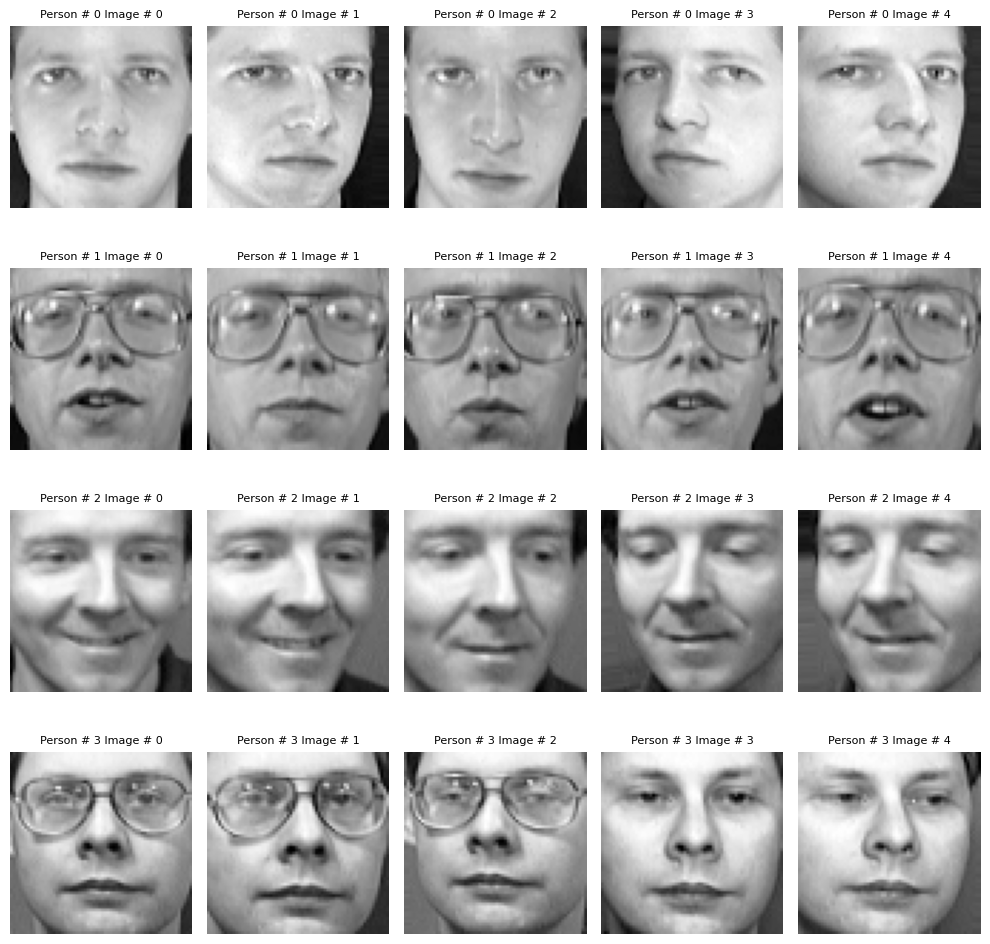

In [3]:
# Visualize the first few principal components as images
# This uses code from to perform visualization: https://marziosala.github.io/eigenfaces/

fig, axes = plt.subplots(figsize=(10, 10), ncols=5, nrows=4)
for i in range(4):
    current = X[y == i]
    for j in range(min(5, len(current))):
        axes[i, j].imshow(current[j].reshape((64, 64)), cmap=plt.cm.gray)
        axes[i, j].set_title(f'Person # {i} Image # {j}', fontsize=8)
    for j in range(5):
        axes[i, j].axis('off')
fig.tight_layout()

# **2. Cumulative Explained Variance & Elbow Plot**

With reference to the code and documentation in [plant_classification.ipynb](https://github.com/bforoura/ML26/blob/main/Module7_Dimensionality/plant_classification.ipynb) notebook, we can determine principal components and the ideal number of them that can explain 95% of the variance in the dataset. Each principal component explains variance with diminishing returns. When plotting the curve, we can determine that 123 principal components explain 95% of the variance in the image dataset. To explain 90% of the variance, 66 principal components (about half) are required and to explain 99% of variance, 260 principal components (more than double) are required.

Number of principal components computed: 400
Variance explained by the first 2 components: 0.3781
Number of components required for 90% variance: 66
Number of components required for 95% variance: 123
Number of components required for 95% variance: 260


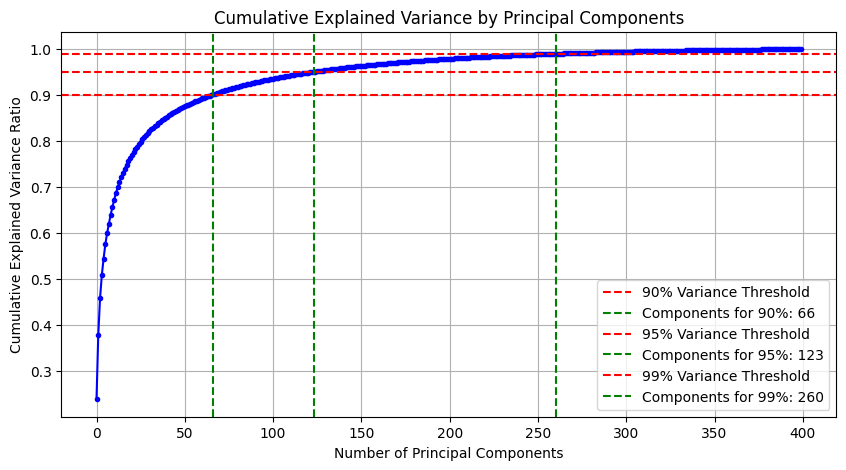

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Initialize PCA and fit on the feature matrix
# Since we have 400 samples, the maximum number of components is min(n_samples, n_features) = 400
pca = PCA(n_components=None)
pca.fit(X)

# Explained variance ratio for each component
explained_variance_ratio = pca.explained_variance_ratio_

# Cumulative explained variance
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

print(f"Number of principal components computed: {len(explained_variance_ratio)}")
print(f"Variance explained by the first 2 components: {cumulative_variance_ratio[1]:.4f}")

# Determine number of components needed for 90% variance
n_components_90 = np.argmax(cumulative_variance_ratio >= 0.90) + 1
print(f"Number of components required for 90% variance: {n_components_90}")

# Determine number of components needed for 95% variance
n_components_95 = np.argmax(cumulative_variance_ratio >= 0.95) + 1
print(f"Number of components required for 95% variance: {n_components_95}")

# Determine number of components needed for 95% variance
n_components_99 = np.argmax(cumulative_variance_ratio >= 0.99) + 1
print(f"Number of components required for 95% variance: {n_components_99}")

# Plotting the Cumulative Explained Variance (Elbow Method)
plt.figure(figsize=(10, 5))
plt.plot(cumulative_variance_ratio, marker='.', linestyle='-', color='b', linewidth=1.5)

#90% Variance
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Variance Threshold')
plt.axvline(x=n_components_90, color='g', linestyle='--', label=f'Components for 90%: {n_components_90}')

#95% Variance
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Variance Threshold')
plt.axvline(x=n_components_95, color='g', linestyle='--', label=f'Components for 95%: {n_components_95}')

#99% Variance
plt.axhline(y=0.99, color='r', linestyle='--', label='99% Variance Threshold')
plt.axvline(x=n_components_99, color='g', linestyle='--', label=f'Components for 99%: {n_components_99}')

plt.title('Cumulative Explained Variance by Principal Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# **3. Image Compression and Reconstruction Analysis**

With reference to the code and documentation in [plant_classification.ipynb](https://github.com/bforoura/ML26/blob/main/Module7_Dimensionality/plant_classification.ipynb) notebook, we can compare one of the images with 4,096 dimensions to its resolution described by 123 principal components. We can see that the image with 123 principal components maintains a number of the same features as the image with 4,096 dimensions. With lower values of K, we cannot make out finer details in the image such as expression and whether the person is wearing glasses.

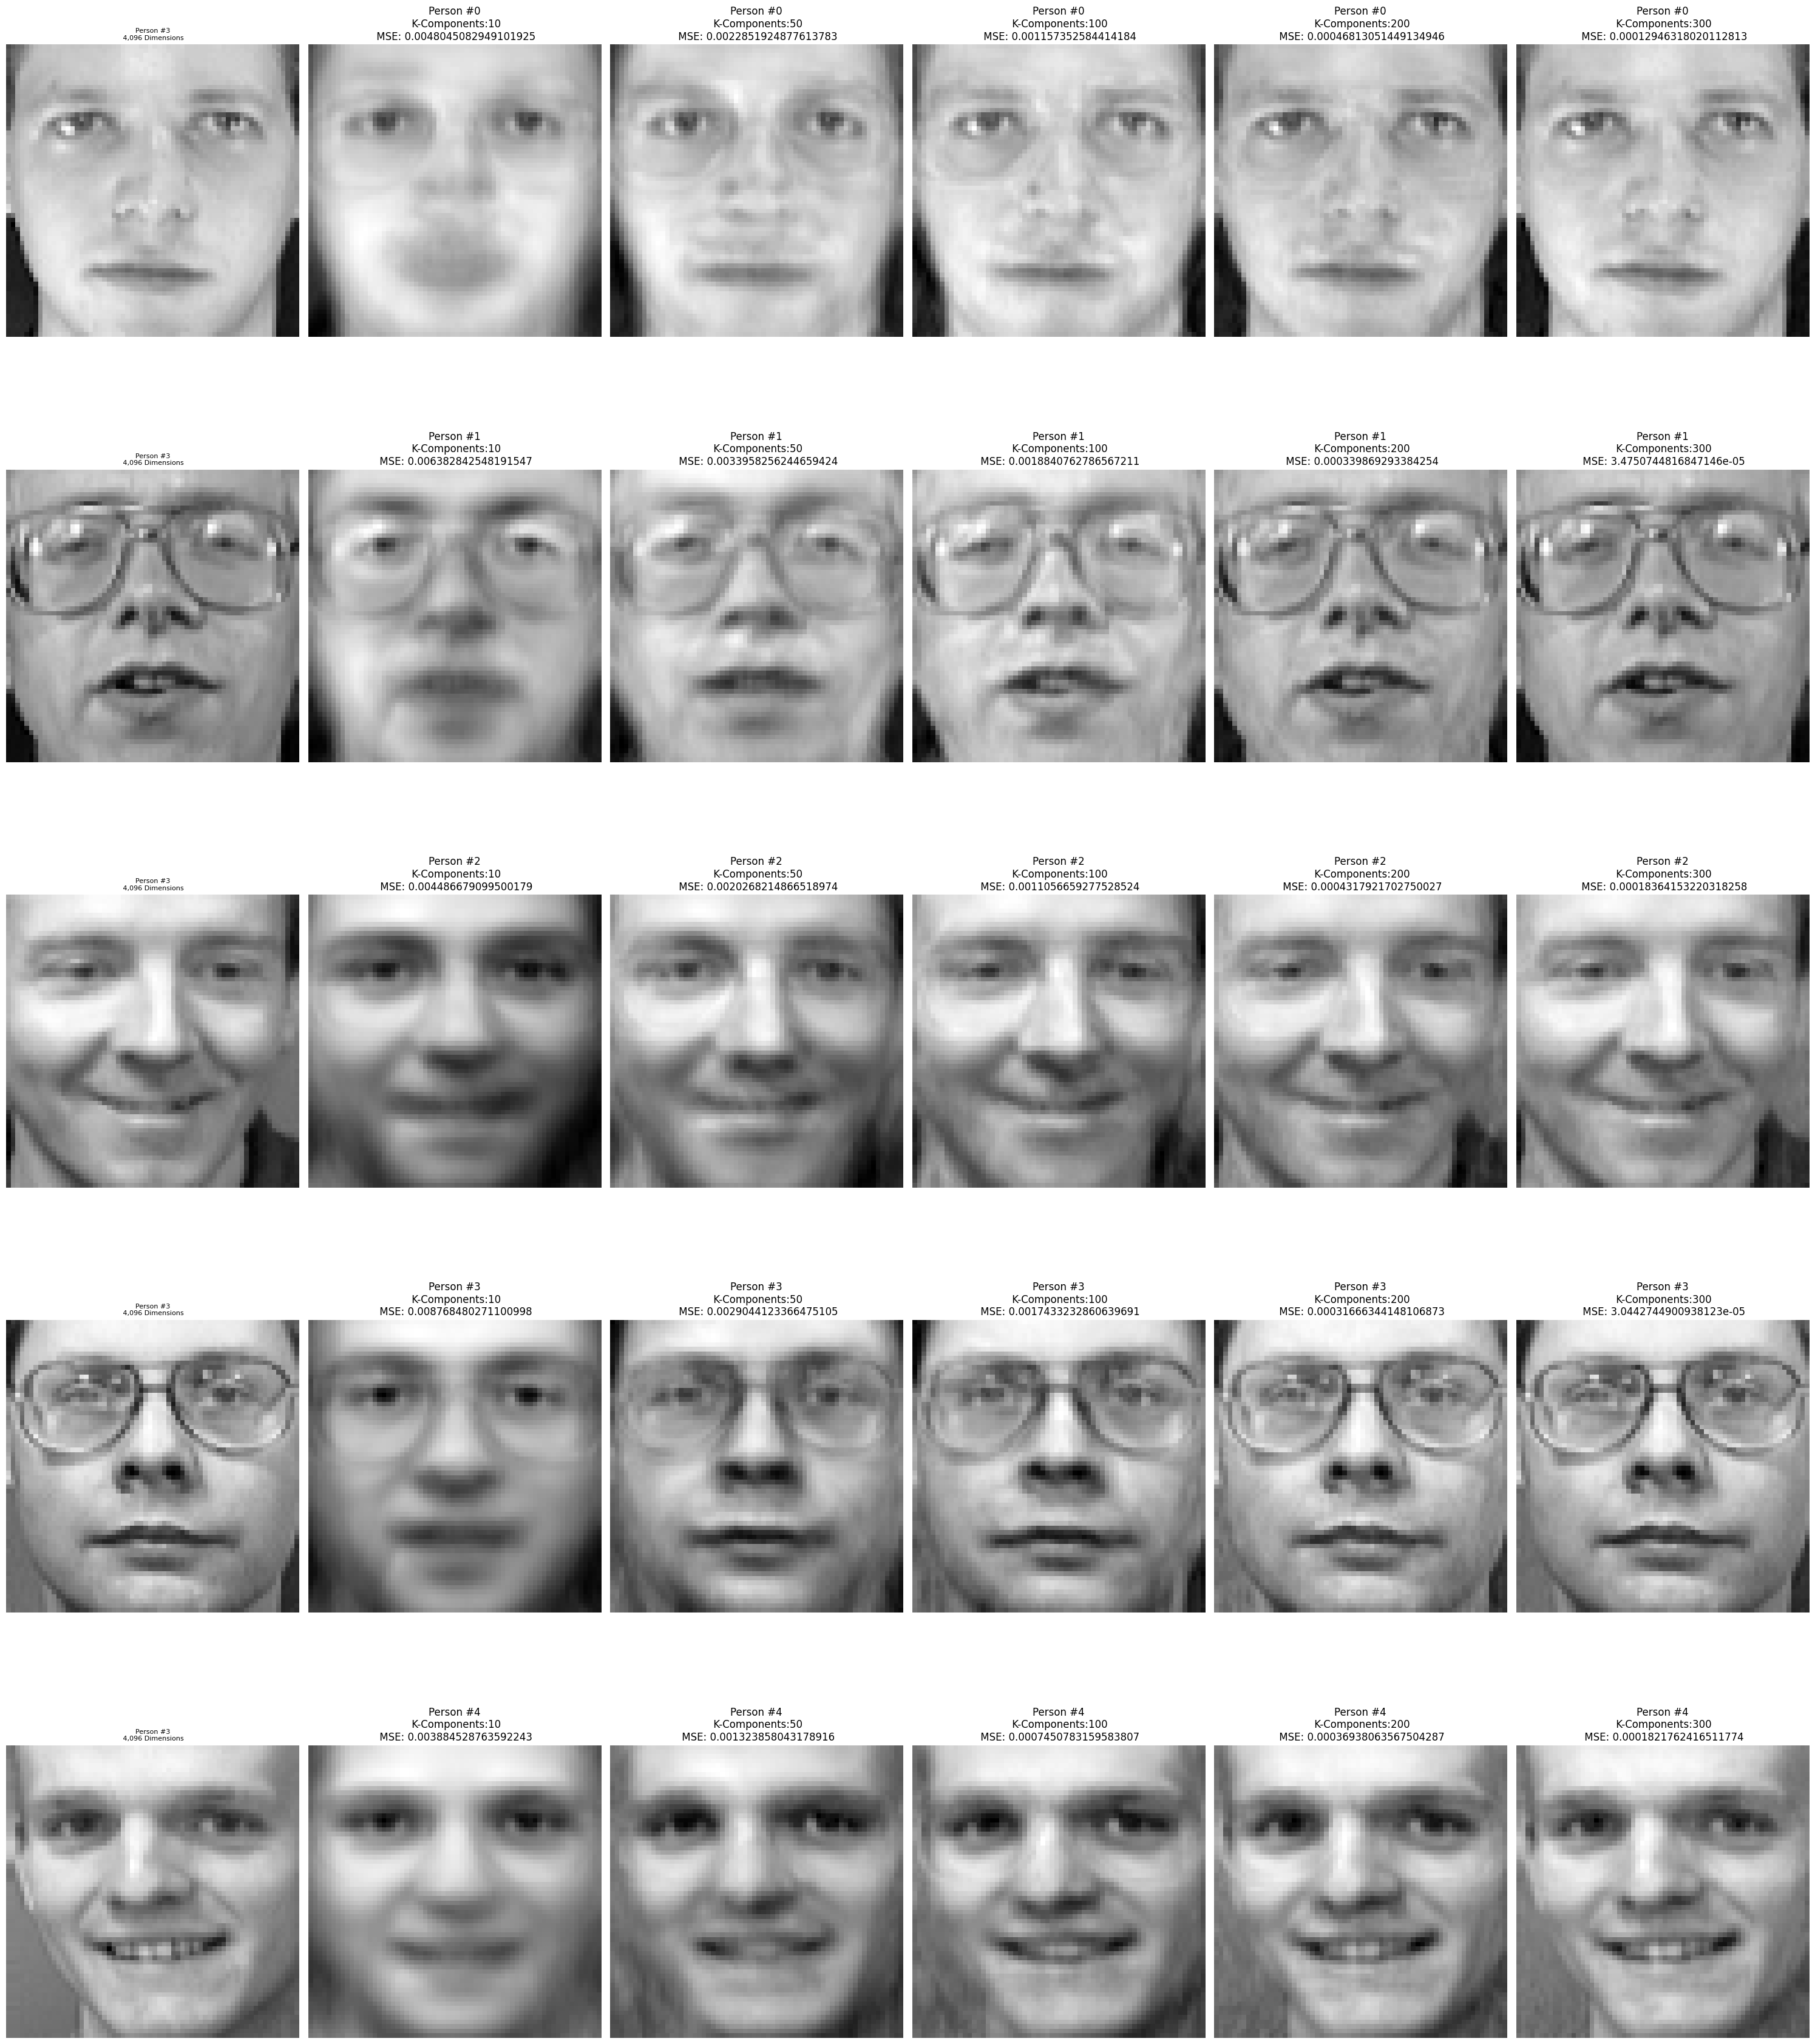

In [5]:
import matplotlib.pyplot as plt
# Project and reconstruct images using the reduced components (4,096 dimensions)
from sklearn.metrics import mean_squared_error

# Plot original vs reconstructed side by side
fig, axes = plt.subplots(5, 6, figsize=(30, 36))
people = [0, 1, 2, 3, 4]
k_settings = [10, 50, 100, 200, 300]

for p in people:
  orig_person = X[y == p]
  #https://www.geeksforgeeks.org/machine-learning/face-completion-with-a-multi-output-estimators-in-scikit-learn/
  original_img = orig_person[0].reshape(64, 64)
  axes[p, 0].imshow(original_img, cmap=plt.cm.gray)
  axes[p, 0].set_title(f'Person #{i}\n 4,096 Dimensions', fontsize=8)
  axes[p, 0].axis('off')
  for k in range(5):
    pca_reduced = PCA(n_components=k_settings[k])
    X_reduced = pca_reduced.fit_transform(X)
    X_reconstructed = pca_reduced.inverse_transform(X_reduced)

    reconstructed_person = X_reconstructed[y == p]
    reconstructed_img = np.clip(reconstructed_person[0].reshape(64, 64))

    #Computing the mean-squared error
    #With reference to: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html
    mse = mean_squared_error(X[y == p][0], X_reconstructed[y == p][0])

    axes[p, k+1].imshow(reconstructed_img, cmap=plt.cm.gray)
    axes[p, k+1].set_title(f'Person #{p}\n K-Components:{k_settings[k]}\n MSE: {mse}')
    axes[p, k+1].axis('off')

plt.tight_layout()
plt.show()

## 4. **Visualization of "Eigenfaces"**

With reference to the code and documentation in [plant_classification.ipynb](https://github.com/bforoura/ML26/blob/main/Module7_Dimensionality/plant_classification.ipynb) notebook, we can visualize what images appear to be with only a few principal components. We can see that most of the shape of each face is captured by the first few principal components but not distinguishing features.

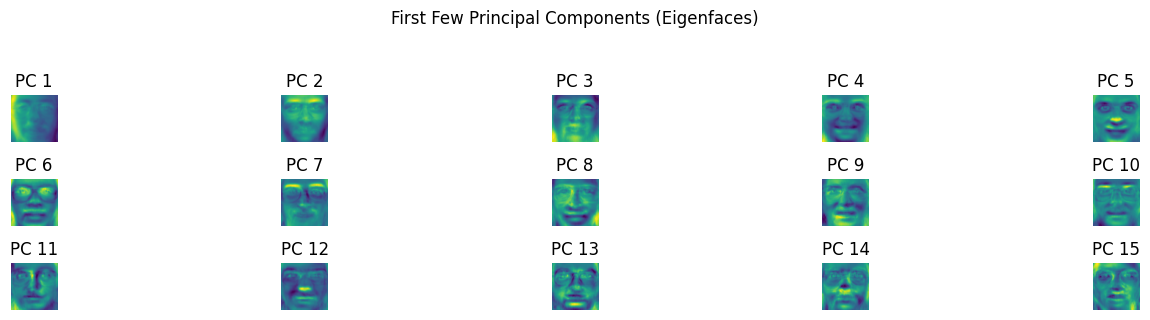

In [6]:
# Visualize the first few principal components as images
num_components_to_plot = 15
fig, axes = plt.subplots(nrows=3, ncols=5, figsize=(15, 3))

c=0

for i in [0, 1, 2]:
  for j in [0, 1, 2, 3, 4]:
    c=c+1
    # Reshape the i-th principal component back into an image shape
    comp_img = pca_reduced.components_[c].reshape(64, 64)

    # Normalize pixel values to [0, 1] for visualization
    comp_img_normalized = (comp_img - comp_img.min()) / (comp_img.max() - comp_img.min())

    axes[i, j].imshow(comp_img_normalized)
    axes[i, j].set_title(f'PC {c}')
    axes[i, j].axis('off')

plt.suptitle('First Few Principal Components (Eigenfaces)', y=1.05)
plt.tight_layout()
plt.show()

# 5. **Task 5: Classification Baseline — Raw vs. PCA-Reduced Features (Linear Model)**

With reference to the code and documentation in [plant_classification.ipynb](https://github.com/bforoura/ML26/blob/main/Module7_Dimensionality/plant_classification.ipynb) notebook, we can compare a Logistic classifier with all 4,096 dimensions a Logistic classifier with PCA transformer. We can chart the differences between the two and we can see that there is a better accuracy score for the PCA transformer but with far less training time.

Training classifier on raw features...
Raw Features Accuracy: 0.9625 (Training time: 16.65s)

Training classifier on PCA-reduced features (123 dimensions)...
PCA-Reduced Features Accuracy: 0.9625 (Training time: 0.69s)


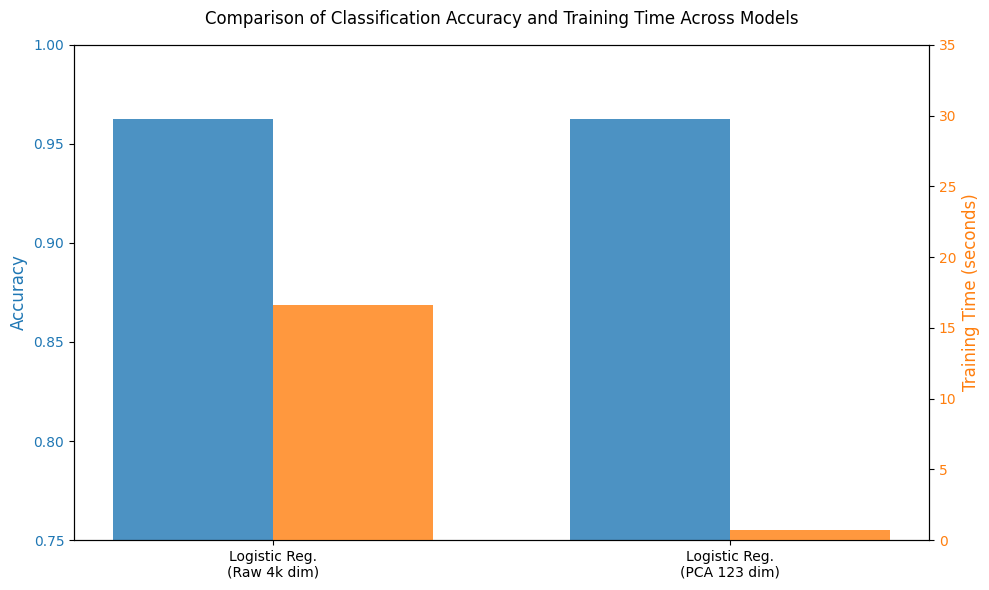

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import time

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Train classifier on Raw Features (4,096 dimensions)
print("Training classifier on raw features...")
start_time = time.time()
clf_raw = LogisticRegression(max_iter=1000, random_state=42)
clf_raw.fit(X_train, y_train)
raw_time = time.time() - start_time

y_pred_raw = clf_raw.predict(X_test)
raw_accuracy = accuracy_score(y_test, y_pred_raw)

print(f"Raw Features Accuracy: {raw_accuracy:.4f} (Training time: {raw_time:.2f}s)")

# 2. Train classifier on PCA-reduced Features (123 dimensions)
print("\nTraining classifier on PCA-reduced features (123 dimensions)...")
start_time = time.time()

# Fit PCA on training data only to avoid data leakage
pca_clf = PCA(n_components=123)
X_train_reduced = pca_clf.fit_transform(X_train)
X_test_reduced = pca_clf.transform(X_test)

clf_pca = LogisticRegression(max_iter=1000, random_state=42)
clf_pca.fit(X_train_reduced, y_train)
pca_time = time.time() - start_time

y_pred_pca = clf_pca.predict(X_test_reduced)
pca_accuracy = accuracy_score(y_test, y_pred_pca)

print(f"PCA-Reduced Features Accuracy: {pca_accuracy:.4f} (Training time: {pca_time:.2f}s)")

# Model results gathered from our experiments
models = [
    'Logistic Reg.\n(Raw 4k dim)',
    'Logistic Reg.\n(PCA 123 dim)',
]

accuracies = [raw_accuracy, pca_accuracy]  # Approximate baseline/tracked values
train_times = [raw_time, pca_time]      # Corresponding training times

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot Accuracy bars on primary y-axis
color = 'tab:blue'
ax1.set_ylabel('Accuracy', color=color, fontsize=12)
bars1 = ax1.bar(x - width/2, accuracies, width, label='Accuracy', color=color, alpha=0.8)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0.75, 1.00)

# Instantiate secondary axis for training time
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Training Time (seconds)', color=color, fontsize=12)
bars2 = ax2.bar(x + width/2, train_times, width, label='Training Time (s)', color=color, alpha=0.8)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, 35)

# Formatting
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=10)
plt.title('Comparison of Classification Accuracy and Training Time Across Models', fontsize=12, pad=15)
fig.tight_layout()
plt.show()

We can see that logistic regression on a PCA-reduced image takes almost 35x less time.

# **Task 6: Non-Linear Classification (Kernel SVM)**

With reference to the code and documentation in [plant_classification.ipynb](https://github.com/bforoura/ML26/blob/main/Module7_Dimensionality/plant_classification.ipynb) notebook, we can compare an PCA transformed, SCV classifier to the performance of a logistic model. Here, we use code and documentation from [spam_nospam_sgdclassifier.ipynb](https://github.com/bforoura/ML26/blob/main/Module3_Classification/spam_nospam_sgdclassifier.ipynb) to create a classification report. We can see that the SVC classifier performs with high accuracy, as well as logistic regression on the raw dataset.




Training classifier on PCA-reduced features (123 dimensions)...
PCA-Reduced Features Accuracy: 0.9625 (Training time: 0.55s)
Classification Report:
              precision    recall  f1-score   support

           0       0.75      1.00      0.86         3
           1       1.00      1.00      1.00         1
           2       1.00      1.00      1.00         2
           3       1.00      0.75      0.86         4
           4       0.75      1.00      0.86         3
           5       1.00      1.00      1.00         3
           7       1.00      0.83      0.91         6
           8       0.67      1.00      0.80         2
           9       1.00      1.00      1.00         2
          10       1.00      1.00      1.00         2
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         1
          14       1.00      1.00      1.00         3
          15       1.00      1.00      1

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


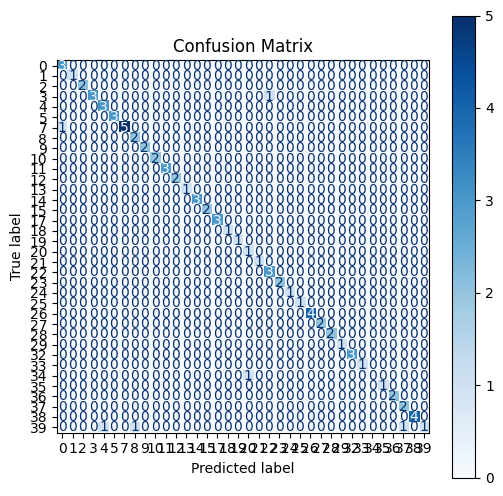

In [8]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train classifier on PCA-reduced Features (123 dimensions)
print("\nTraining classifier on PCA-reduced features (123 dimensions)...")
start_time = time.time()

# Fit PCA on training data only to avoid data leakage
pca_clf = PCA(n_components=123)
X_train_reduced = pca_clf.fit_transform(X_train)
X_test_reduced = pca_clf.transform(X_test)

svc_pca = SVC(kernel='rbf', probability=True, random_state=42)
svc_pca.fit(X_train_reduced, y_train)
svc_pca_time = time.time() - start_time

y_pred_svc_pca = clf_pca.predict(X_test_reduced)
svc_pca_accuracy = accuracy_score(y_test, y_pred_pca)

print(f"PCA-Reduced Features Accuracy: {svc_pca_accuracy:.4f} (Training time: {svc_pca_time:.2f}s)")

# Fit the entire pipeline on the training data
svc_pca.fit(X_train, y_train)

# Generate predictions and probability scores on the test set
y_pred = svc_pca.predict(X_test)
y_scores = svc_pca.predict_proba(X_test)[:, 1]

# Print classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_estimator(svc_pca, X_test, y_test, ax=ax, cmap='Blues', values_format='d')
plt.title('Confusion Matrix')
plt.show()

## **7. Ensemble Classification on PCA Features**

With reference to the code and documentation in [plant_classification.ipynb](https://github.com/bforoura/ML26/blob/main/Module7_Dimensionality/plant_classification.ipynb) notebook, we can create an ensemble classifier for a polynomial svc, an rbf kernal svc, and a random forest. This ensemble classifier underperforms others but a 95% accuracy score shows that this ensemble classifier is reliable.

In [9]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import time

print("Training Ensemble Classifier on PCA-reduced features (126 dimensions)...")
start_time = time.time()

# Define individual estimators
poly_svm = SVC(kernel='poly', degree=2, probability=True, random_state=42)
rbf_svm = SVC(kernel='rbf', probability=True, random_state=42)
random_forest = RandomForestClassifier(n_estimators=100, random_state=42)

# Create the Voting Classifier (using soft voting to average predicted probabilities)
ensemble_clf = VotingClassifier(
    estimators=[
        ('poly_svm', poly_svm),
        ('rbf_svm', rbf_svm),
        ('random_forest', random_forest)
    ],
    voting='soft'
)

# Train the ensemble
ensemble_clf.fit(X_train_reduced, y_train)
ensemble_time = time.time() - start_time

# Evaluate performance
y_pred_ensemble = ensemble_clf.predict(X_test_reduced)
ensemble_accuracy = accuracy_score(y_test, y_pred_ensemble)

print(f"Ensemble Classifier Accuracy: {ensemble_accuracy:.4f} (Training time: {ensemble_time:.2f}s)")

Training Ensemble Classifier on PCA-reduced features (126 dimensions)...
Ensemble Classifier Accuracy: 0.9750 (Training time: 0.66s)


## **8. Comprehensive Comparative Evaluation**

With reference to the code and documentation in [plant_classification.ipynb](https://github.com/bforoura/ML26/blob/main/Module7_Dimensionality/plant_classification.ipynb) notebook, we can visualize the performance and accuracy of all three models. We can see that all models perform with similar accuracy but the the PCA transformer drastically reduces training time. We can see that the svc classifier trained the fastest and the ensemble classifier had the best performance.

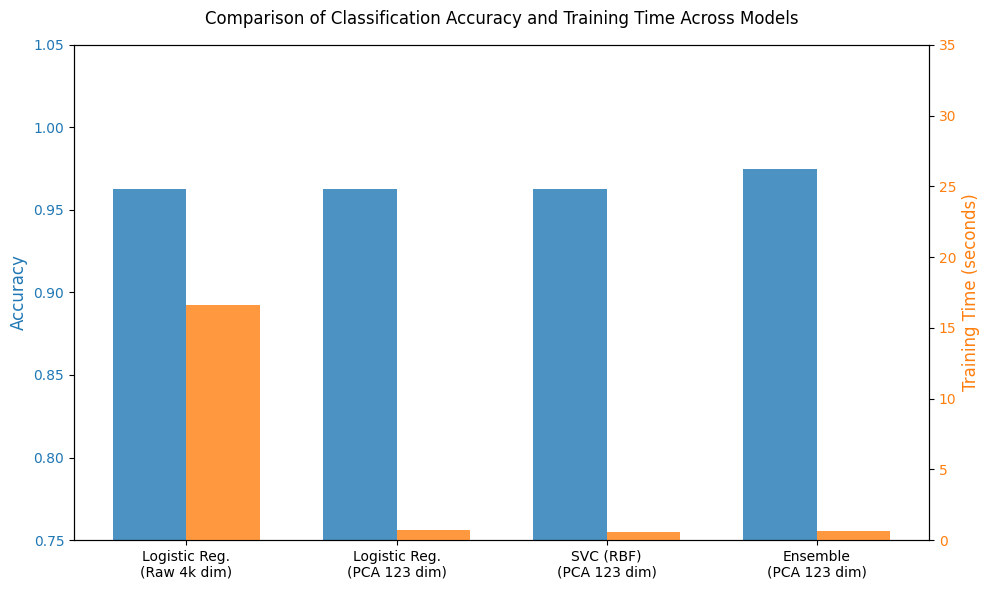

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Model results gathered from our experiments
models = [
    'Logistic Reg.\n(Raw 4k dim)',
    'Logistic Reg.\n(PCA 123 dim)',
    'SVC (RBF)\n(PCA 123 dim)',
    'Ensemble\n(PCA 123 dim)'
]

accuracies = [raw_accuracy, pca_accuracy, svc_pca_accuracy, ensemble_accuracy]  # Approximate baseline/tracked values
train_times = [raw_time, pca_time, svc_pca_time, ensemble_time]      # Corresponding training times

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot Accuracy bars on primary y-axis
color = 'tab:blue'
ax1.set_ylabel('Accuracy', color=color, fontsize=12)
bars1 = ax1.bar(x - width/2, accuracies, width, label='Accuracy', color=color, alpha=0.8)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0.75, 1.05)

# Instantiate secondary axis for training time
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Training Time (seconds)', color=color, fontsize=12)
bars2 = ax2.bar(x + width/2, train_times, width, label='Training Time (s)', color=color, alpha=0.8)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, 35)

# Formatting
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=10)
plt.title('Comparison of Classification Accuracy and Training Time Across Models', fontsize=12, pad=15)
fig.tight_layout()
plt.show()